In [1]:
import xarray as xr
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.util as cutil
import numpy as np
from tqdm import tqdm
import matplotlib.gridspec as gridspec  # To control widths
from scipy.integrate import trapezoid

In [2]:
#here we focus on the asymmetric baseline simulation
%cd /home/links/mf671/DATA/ERA5/falwa_data/

/home/links/mf671/DATA/ERA5/falwa_data


In [3]:
#import dataset with fluxes (output of falwa)
data = xr.open_mfdataset('/home/links/mf671/DATA/ERA5/falwa_data/falwa_output_per_month/falwa_output_daily_1.5x1.5_*.nc',parallel=True)
ucomp_ERA5 = data['u_baro'] - data['dw_uref']
lwa_ERA5 = data['dw_lwa']
qgpv_ERA5 = data['dw_qgpv']
qref_ERA5 = data['dw_qref']
F1_ERA5 = data['adv_flux_f1'].copy()
F2_ERA5 = data['adv_flux_f2'].copy()
F3_ERA5 = data['adv_flux_f3'].copy()
lon = data['longitude']
lat = data['latitude']

print(len(data.valid_time))
data.close()

1805


/home/links/mf671/miniconda3/envs/prog_env/lib/python3.13/site-packages/dask/_task_spec.py:741: RuntimeWarning: invalid value encountered in subtract
  return self.func(*new_argspec)
/home/links/mf671/miniconda3/envs/prog_env/lib/python3.13/site-packages/dask/_task_spec.py:741: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)


### Necessary functions

In [10]:
from scipy.signal import butter, filtfilt

import xarray as xr
import numpy as np

import xarray as xr

import xarray as xr

def rolling_periodic(
    da: xr.DataArray,
    dim: str,
    window: int,
    center: bool = True
) -> xr.DataArray:

    n = window // 2 if center else window - 1

    # Extend array by wrapping values from both ends along chosen dimension
    da_extended = xr.concat([da.isel({dim: slice(-n, None)}),
                             da,
                             da.isel({dim: slice(0, n)})],
                            dim=dim)

    # Apply rolling mean
    rolled = da_extended.rolling({dim: window}, center=center).mean()

    # Trim back to original length
    result = rolled.isel({dim: slice(n, -n)})
    result[dim] = da[dim]  # restore original coords

    return result

def lowpass_fourier(da, period_days=4 , dt=1, time_dim='valid_time'):
    
    n_time = da.sizes[time_dim]

    # FFT frequencies (cycles per day)
    freqs = np.fft.fftfreq(n_time, d=dt)
    cutoff = 1 / period_days  # max frequency to keep

    # FFT along time axis
    fft_vals = np.fft.fft(da, axis=0)

    # Low-pass mask
    mask = np.abs(freqs) <= cutoff
    fft_vals_filtered = fft_vals * mask[:, np.newaxis, np.newaxis]

    # Inverse FFT
    filtered_data = np.fft.ifft(fft_vals_filtered, axis=0).real

    return xr.DataArray(filtered_data, dims=da.dims, coords=da.coords, name=da.name)

def longitude_running_avg(da, lon_window_deg=15, lon_dim='longitude'):
    # Compute number of points corresponding to lon_window_deg
    lon_vals = da[lon_dim].values
    if len(lon_vals) > 1:
        lon_res = np.mean(np.diff(lon_vals))
        window_points = max(1, int(np.round(lon_window_deg / lon_res)))
    else:
        window_points = 1

    print('longitudinal filter window: '+ str(window_points))

    # Apply rolling mean along longitude
    da_smoothed = rolling_periodic(da, lon_dim , window = window_points, center=True)
    return da_smoothed

def deseasonalize_daily(da):
    daily_clim = da.groupby("valid_time.dayofyear").mean("valid_time")
    anomalies = da.groupby("valid_time.dayofyear") - daily_clim    
    return anomalies

def deseasonalize_roll(da):
    running_mean = rolling_periodic(da=da,dim='valid_time',window=30,center=True)
    mean = da.mean(dim='valid_time')
    anomalies = da - running_mean + mean 
    return anomalies

def deseasonalize_harmonic(da, n_harmonics=3, time_dim='valid_time'):
    """
    Remove the seasonal cycle following Barpanda & Nakamura (2025, Sec. 3a):
    "we subtract the seasonal cycle from the daily averaged time series which
    is computed using the first three annual harmonics of the daily means of
    the entire dataset."

    Same input/output contract as `deseasonalize_roll`: takes a DataArray
    with a time dimension `time_dim`, returns anomalies with the overall
    time-mean added back on (so the output's long-term mean matches the
    input's, not zero).
    """
    # 1. Daily climatology: mean value for each day-of-year (1..365/366),
    #    computed over the full input period (matches "entire dataset").
    daily_clim = da.groupby(f"{time_dim}.dayofyear").mean(time_dim)

    # 2. Keep only the annual mean (freq 0) + the first n_harmonics
    #    (freq 1..n_harmonics cycles/year) of that climatology.
    axis = daily_clim.get_axis_num('dayofyear')
    n = daily_clim.sizes['dayofyear']

    fft_vals = np.fft.fft(daily_clim.values, axis=axis)

    mask = np.zeros(n, dtype=bool)
    mask[0] = True                      # annual mean
    for k in range(1, n_harmonics + 1):
        mask[k] = True                  # +k cycles/year
        mask[-k] = True                 # matching negative frequency

    mask_shape = [1] * fft_vals.ndim
    mask_shape[axis] = n
    fft_vals_filtered = fft_vals * mask.reshape(mask_shape)

    smooth_clim_vals = np.fft.ifft(fft_vals_filtered, axis=axis).real
    smooth_clim = xr.DataArray(
        smooth_clim_vals,
        dims=daily_clim.dims,
        coords=daily_clim.coords,
        name=da.name,
    )

    # 3. Map the smoothed seasonal cycle back onto the full time axis via
    #    day-of-year (vectorized indexing: output dims follow `doy`, i.e.
    #    time_dim, not 'dayofyear').
    doy = da[time_dim].dt.dayofyear
    seasonal_cycle = smooth_clim.sel(dayofyear=doy)

    # 4. Anomalies, with the overall time-mean added back — same convention
    #    as deseasonalize_roll, so it's a drop-in replacement.
    overall_mean = da.mean(dim=time_dim)
    anomalies = da - seasonal_cycle + overall_mean

    return anomalies

In [11]:
def fit_alpha_beta_gamma_origin(A, F2, cosphi, dim='valid_time', scale=100.0,
                                min_cos=0.05, min_samples=50):
    """
    Joint least-squares fit through the origin, per grid point:
        F2/cosphi = beta*A - alpha*A**2 + gamma*A**3
    A      : lwa/cosphi (m/s)
    F2     : filtered F2
    cosphi : cos(latitude), broadcast like A
    scale  : A is divided by this before fitting (A, A^2, A^3 are strongly
             collinear, so rescaling improves conditioning); coefficients
             are rescaled back afterwards.
    """
    y = F2 / cosphi
    a = A / scale

    # same valid samples for every regressor (and drop cos(phi) ~ 0 near the pole)
    valid = np.isfinite(a) & np.isfinite(y) & (cosphi > min_cos)
    a = a.where(valid)
    y = y.where(valid)
    n = valid.sum(dim)

    X = [a, a**2, a**3]

    # uncentered moments: G_ij = <X_i X_j>, b_i = <X_i y>   (no mean removal!)
    G = xr.concat(
        [xr.concat([(X[i] * X[j]).mean(dim) for j in range(3)], dim='j')
         for i in range(3)], dim='i')
    b = xr.concat([(X[i] * y).mean(dim) for i in range(3)], dim='i')

    G = G.compute()
    b = b.compute()
    n = n.compute()

    def _solve(G, b):
        # G: (..., 3, 3), b: (..., 3)
        bad = ~np.isfinite(G).all(axis=(-1, -2)) | ~np.isfinite(b).all(axis=-1)
        G = np.where(bad[..., None, None], np.eye(3), G)
        b = np.where(bad[..., None], 0.0, b)
        c = np.linalg.solve(G, b[..., None])[..., 0]
        c[bad] = np.nan
        return c

    c = xr.apply_ufunc(
        _solve, G, b,
        input_core_dims=[['i', 'j'], ['i']],
        output_core_dims=[['i']],
        output_dtypes=[float],
    )

    # undo the scaling: coefficient of A^k is c_k / scale^k
    beta  = c.isel(i=0) / scale
    alpha = -c.isel(i=1) / scale**2
    gamma = c.isel(i=2) / scale**3

    # too few samples -> mask out
    ok = n >= min_samples
    beta, alpha, gamma = beta.where(ok), alpha.where(ok), gamma.where(ok)

    return alpha.rename('alpha_F2'), beta.rename('beta_F2'), gamma.rename('gamma_F2')

In [12]:
def compute_covariance_xr(A,B):
    
    #A = A.where(np.isfinite(A), 0)
    #B = B.where(np.isfinite(B), 0)
    #A = A.where(np.isnan(A), 0)
    #B = B.where(np.isnan(B), 0)
    
    # Compute means lazily (Dask-aware)
    A_mean = A.mean(dim='valid_time')
    B_mean = B.mean(dim='valid_time')
    
    # Compute anomalies lazily
    A_anom = A - A_mean
    B_anom = B - B_mean
    
    # Covariance calculation
    cov = (A_anom * B_anom).mean(dim='valid_time')
    return cov
        

## Filtering data

In [13]:
print('applying filters')
cosphi = np.cos(np.deg2rad(lat)).broadcast_like(ucomp_ERA5)
lwa = longitude_running_avg(lowpass_fourier(deseasonalize_harmonic(lwa_ERA5)))
ucomp = longitude_running_avg(lowpass_fourier(deseasonalize_harmonic(ucomp_ERA5)))
F1 = longitude_running_avg(lowpass_fourier(deseasonalize_harmonic(F1_ERA5)))
F2 = longitude_running_avg(lowpass_fourier(deseasonalize_harmonic(F2_ERA5)))
F3 = longitude_running_avg(lowpass_fourier(deseasonalize_harmonic(F3_ERA5)))
zonal_flux = (F1_ERA5 + F3_ERA5)
tot_zonal_flux = (F1_ERA5 + F2_ERA5 + F3_ERA5)

applying filters
longitudinal filter window: 10
longitudinal filter window: 10
longitudinal filter window: 10
longitudinal filter window: 10


/home/links/mf671/miniconda3/envs/prog_env/lib/python3.13/site-packages/numpy/fft/_pocketfft.py:94: RuntimeWarning: invalid value encountered in fft
  return ufunc(a, fct, axes=[(axis,), (), (axis,)], out=out)
/tmp/ipykernel_1650099/65671280.py:111: RuntimeWarning: invalid value encountered in multiply
  fft_vals_filtered = fft_vals * mask.reshape(mask_shape)


longitudinal filter window: 10


/home/links/mf671/miniconda3/envs/prog_env/lib/python3.13/site-packages/dask/_task_spec.py:741: RuntimeWarning: invalid value encountered in multiply
  return self.func(*new_argspec)


## Computing $\alpha$, $\beta$, $\gamma$

In [17]:
A_nc = lwa / cosphi
alpha, beta, gamma = fit_alpha_beta_gamma_origin(A_nc, F2, cosphi)

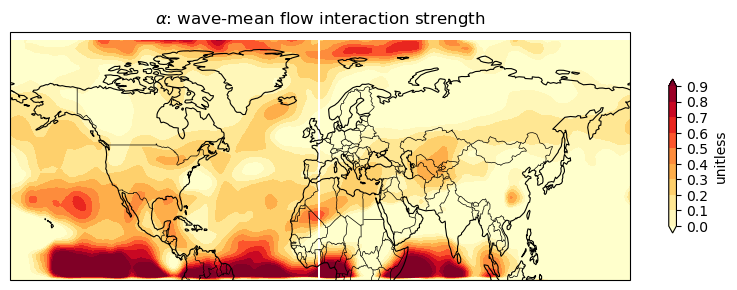

In [18]:
import cartopy.feature as cfeature

fig, ax = plt.subplots(subplot_kw={'projection': ccrs.PlateCarree()}, figsize=(10, 4))

# Set extent: lon from -180 to 180, lat from 25 to 75
ax.set_extent([-180, 180, 0, 90], crs=ccrs.PlateCarree())

# Plot the filled contours
contour = ax.contourf(
    lon, lat, alpha_F2,
    levels=np.arange(0,1,0.1),
    cmap='YlOrRd',
    extend='both',
    transform=ccrs.PlateCarree()
)

# Add coastlines and optional borders
ax.set_aspect(1.6)
ax.coastlines(color='black', linewidth=0.8)
ax.add_feature(cfeature.BORDERS, linewidth=0.5)

# Add colorbar
cbar = plt.colorbar(contour, ax=ax, orientation='vertical', label='unitless',shrink=0.5)
plt.title(r'$\alpha$: wave-mean flow interaction strength')

plt.show()

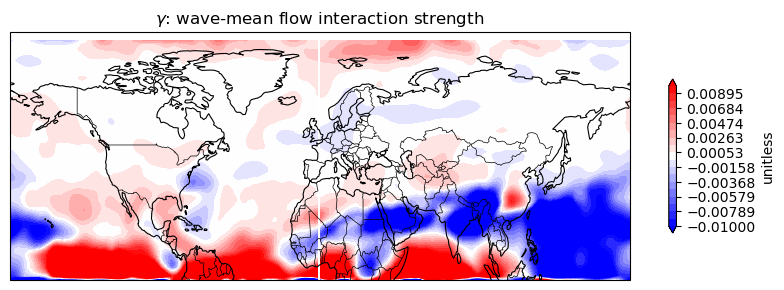

In [19]:
import cartopy.feature as cfeature

fig, ax = plt.subplots(subplot_kw={'projection': ccrs.PlateCarree()}, figsize=(10, 4))

# Set extent: lon from -180 to 180, lat from 25 to 75
ax.set_extent([-180, 180, 0, 90], crs=ccrs.PlateCarree())

order_of_magnitude = 2

# Plot the filled contours
contour = ax.contourf(
    lon, lat, gamma_F2,
    levels=np.linspace(-10**(-order_of_magnitude),+10**(-order_of_magnitude),20),
    cmap='bwr',
    extend='both',
    transform=ccrs.PlateCarree()
)

# Add coastlines and optional borders
ax.set_aspect(1.6)
ax.coastlines(color='black', linewidth=0.8)
ax.add_feature(cfeature.BORDERS, linewidth=0.5)

# Add colorbar
cbar = plt.colorbar(contour, ax=ax, orientation='vertical', label='unitless',shrink=0.5)
plt.title(r'$\gamma$: wave-mean flow interaction strength')

plt.show()

## Computing $u_{ref} + c_g$

$u_0 + c_g^x$ is computed as a regression coefficient between vertically-averaged linear zonal LWA flux $(𝐹_1 + 𝐹_3)$ and the wave-activity $(A cos\phi)$

In [20]:
print('computing covariances')
cov = compute_covariance_xr(lwa,zonal_flux)
var = compute_covariance_xr(lwa,lwa)
ds_zon_group_velocity = (cov/var).persist()

# Compute the intercept (F0) of the linear relationship: (F1+F2)cosphi ≈ (u_REF+C_g) * (lwa) + F0
zonal_flux_mean = zonal_flux.mean(dim='valid_time')
lwa_mean = lwa.mean(dim='valid_time')
F0 = (zonal_flux_mean - ds_zon_group_velocity * lwa_mean).persist()

computing covariances


In [21]:
print('performing zonal average')
da_avg = ds_zon_group_velocity.mean(axis=-1).values
GV_zon_mean = np.broadcast_to(da_avg[:, np.newaxis], ds_zon_group_velocity.shape)

performing zonal average


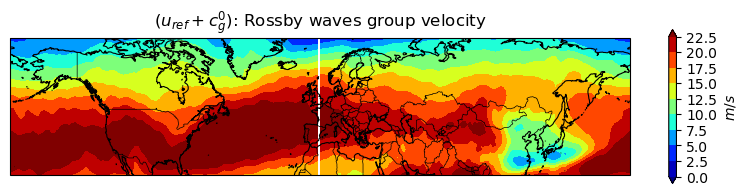

In [22]:
import cartopy.feature as cfeature

fig, ax = plt.subplots(subplot_kw={'projection': ccrs.PlateCarree()}, figsize=(10, 4))

# Set extent: lon from -180 to 180, lat from 25 to 75
ax.set_extent([-180, 180, 25, 75], crs=ccrs.PlateCarree())

# Plot the filled contours
contour = ax.contourf(
    lon,lat,ds_zon_group_velocity,
    levels=np.arange(0, 24, 2.5),
    cmap='jet',#'YlOrRd',
    extend='both',
    transform=ccrs.PlateCarree()
)

# Add coastlines and optional borders
ax.set_aspect(1.6)
ax.coastlines(color='black', linewidth=0.8)
ax.add_feature(cfeature.BORDERS, linewidth=0.5)

# Add colorbar
cbar = plt.colorbar(contour, ax=ax, orientation='vertical', label='$m/s$',shrink=0.5)
plt.title('$(u_{ref} + c^0_g)$: Rossby waves group velocity')

plt.show()

## Computing $A_0$

The stationary wave component of A0 can be roughly estimated through its mean value. Otherwise a more refined method would be to exclude the grid points during which blocking is happening. In this way, the stationary waves are not influenced by blocking and it is easier to assess causality relationship. In this case we are sticking to the first way because we didn't compute blocking climatology for ERA5

In [23]:
from math import pi
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
import datetime as dt
from scipy.integrate import trapezoid
from tqdm import tqdm

# --- Parameters --- #
Earth_radius = 6.378e+6 # Earth's radius

# --- Load the zonal wind and QGPV at 240hPa --- #
QGPV_File = xr.open_dataset('/home/links/mf671/DATA/ERA5/falwa_data/qgpv_qref_monthly_djf_1980-2000.nc')

# --- Read in longitude and latitude arrays --- #
xlon = QGPV_File.longitude.values
ylat = QGPV_File.latitude.values
height = QGPV_File.height.values
time = QGPV_File.valid_time.values
clat = np.abs(np.cos(ylat*pi/180.)) # cosine latitude
nlon = xlon.size
nlat = ylat.size

# --- Parameters needed to use the module HN2015_LWA --- 
dphi = (ylat[2]-ylat[1])*pi/180. # Equal spacing between latitude grid points, in radian
area = 2.*pi*Earth_radius**2 *(np.cos(ylat[:,np.newaxis]*pi/180.)*dphi)/float(nlon) * np.ones((nlat,nlon))
area = np.abs(area) # To make sure area element is always positive (given floating point errors).

# --- Read in the absolute vorticity field from the netCDF file --- #
QGPV = QGPV_File.qgpv
Qref_input = QGPV_File.qref

p0 = 1000.                          # surface pressure [hPa]
kmax = 96                           # number of grid points for vertical extrapolatitudeion (dimension of height)
dz = 500.                          # differential height element
height = np.arange(0,kmax)*dz       # pseudoheight [m]
hh = 6745.                          # scale height
    
prefactor = np.array([np.exp(-z/hh) for z in height[1:]]).sum() # integrated sum of density from the level
                                                                #just above the ground (z=1km) to aloft
coeff = np.array([np.exp(-z/hh) for z in height[1:]])

print('averaging qgpv')
density_weighted_qgpv = np.sum(coeff[np.newaxis,:,np.newaxis,np.newaxis]*QGPV[:,1:,:,:],axis=1)/prefactor
print(density_weighted_qgpv.shape)

print('averaging qref')
density_weighted_qref = np.sum(coeff[np.newaxis,:,np.newaxis]*Qref_input[:,1:,:],axis=1)/prefactor
print(density_weighted_qref.shape)

# initialize LWA value
LWA = density_weighted_qgpv.copy()
LWA.values = np.zeros(density_weighted_qgpv.shape)

averaging qgpv
(60, 121, 240)
averaging qref
(60, 121)


#METHOD 1

#my own classes
import sys
sys.path.append("/emmy-noether/home/mf671/github/hn2016_falwa/src/falwa/")
from wrapper import qgpv_eqlat_lwa

for i,t in tqdm(enumerate(time)):
    Qref_tmp, LWA_tmp = qgpv_eqlat_lwa(ylat=ylat, vort=density_weighted_qgpv.loc[t,:,:].values,area=area,dmu=Earth_radius*clat*dphi,n_points=30,qref=density_weighted_qref.loc[t,:].values)
    LWA.loc[t,:,:] = LWA_tmp
        
density_weighted_stat_lwa_1 = LWA.mean('valid_time')

In [24]:
#METHOD 2

#my own classes
import sys
sys.path.append("/emmy-noether/home/mf671/github/hn2016_falwa/src/falwa/")
from wrapper import barotropic_input_qref_to_compute_lwa

def compute_dw_stat_lwa(dw_qgpv,dw_qref):
   # --- Parameters --- #
    Earth_radius = 6.378e+6 # Earth's radius
    # --- Read in longitude and latitude arrays --- #
    lon = dw_qgpv.longitude.values
    lat = dw_qgpv.latitude.values
    clat = np.abs(np.cos(lat*pi/180.)) # cosine latitude
    nlon = lon.size
    nlat = lat.size
    
    # --- Parameters needed to use the module HN2015_LWA --- 
    dphi = (lat[2]-lat[1])*pi/180. # Equal spacing between latitude grid points, in radian
    area = 2.*pi*Earth_radius**2 *(np.cos(lat[:,np.newaxis]*pi/180.)*dphi)/float(nlon) * np.ones((nlat,nlon))
    area = np.abs(area) # To make sure area element is always positive (given floating point errors).
    
    # --- Read in the absolute vorticity field from the netCDF file --- #
    density_weighted_qgpv = dw_qgpv.mean('valid_time')
    density_weighted_qref = dw_qref.mean('valid_time')
    
    return barotropic_input_qref_to_compute_lwa(ylat=lat, qref=density_weighted_qref, vort=density_weighted_qgpv, area=area, dmu=Earth_radius*clat*dphi)[0]

density_weighted_stat_lwa_2 = alpha.copy() #initiliaze as a data array with the right dimensions
density_weighted_stat_lwa_2.values = compute_dw_stat_lwa(density_weighted_qgpv,density_weighted_qref)

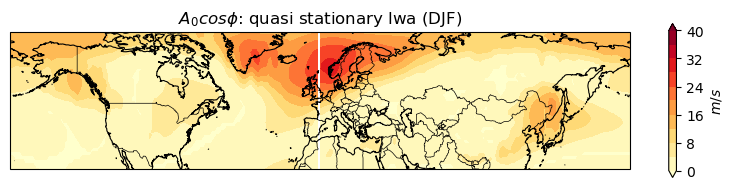

In [25]:
import cartopy.feature as cfeature

fig, ax = plt.subplots(subplot_kw={'projection': ccrs.PlateCarree()}, figsize=(10, 4))

# Set extent: lon from -180 to 180, lat from 25 to 75
ax.set_extent([-180, 180, 25, 75], crs=ccrs.PlateCarree())

# Plot the filled contours
contour = ax.contourf(
    xlon,ylat,density_weighted_stat_lwa_2,
    levels=np.arange(0, 42, 4),
    cmap='YlOrRd',
    extend='both',
    transform=ccrs.PlateCarree()
)

# Add coastlines and optional borders
ax.set_aspect(1.6)
ax.coastlines(color='black', linewidth=0.8)
ax.add_feature(cfeature.BORDERS, linewidth=0.5)

# Add colorbar
cbar = plt.colorbar(contour, ax=ax, orientation='vertical', label='$m/s$',shrink=0.5)
plt.title(r'$A_0 cos\phi$: quasi stationary lwa (DJF)')

plt.show()

## TEST OF FLUXES APPROXIMATION

In [26]:
#Testing the fluxes approximation 

location_for_test = -10.5,51 #region of maximum covariance
#location_for_test = -70,25 #storm track entrance
#location_for_test = 10,55 #region of European blocking


#lwa_prime = (lwa-density_weighted_stat_lwa_2[np.newaxis,:,:])/cosphi
lwa_prime_1D = (lwa/cosphi).sel(latitude=location_for_test[1], longitude=location_for_test[0], method='nearest').values
cosphi_1D = np.cos(np.deg2rad(location_for_test[1]))
u0_1D = data['dw_uref'].mean('valid_time').sel(latitude=location_for_test[1], method='nearest').values
F0_1D = F0.sel(latitude=location_for_test[1], longitude=location_for_test[0], method='nearest').values
alpha_1D = alpha.sel(latitude=location_for_test[1], longitude=location_for_test[0], method='nearest').values
beta_1D = beta.sel(latitude=location_for_test[1], longitude=location_for_test[0], method='nearest').values
gamma_1D = gamma.sel(latitude=location_for_test[1], longitude=location_for_test[0], method='nearest').values
cg_1D = (ds_zon_group_velocity-data['dw_uref'].mean('valid_time')).sel(latitude=location_for_test[1], longitude=location_for_test[0], method='nearest').values
ds_zon_group_velocity_1D = ds_zon_group_velocity.sel(latitude=location_for_test[1], longitude=location_for_test[0], method='nearest').values
density_weighted_stat_lwa_2_1D = density_weighted_stat_lwa_2.sel(latitude=location_for_test[1], longitude=location_for_test[0], method='nearest').values

#COMPUTING F2
F2_approx = ((-lwa_prime_1D*alpha_1D + beta_1D)*lwa_prime_1D*cosphi_1D)# + gamma_1D*(lwa_prime_1D**3)*cosphi_1D
#F2_approx = ((-lwa_prime_1D*alpha_1D)*lwa_prime_1D*cosphi_1D)

#COMPUTING F1+F3
F1F3_approx = (ds_zon_group_velocity_1D*lwa_prime_1D*cosphi_1D + F0_1D)
#F1F3_approx = (ds_zon_group_velocity_1D*lwa_prime_1D*cosphi_1D)

NameError: name 'neg_cov' is not defined

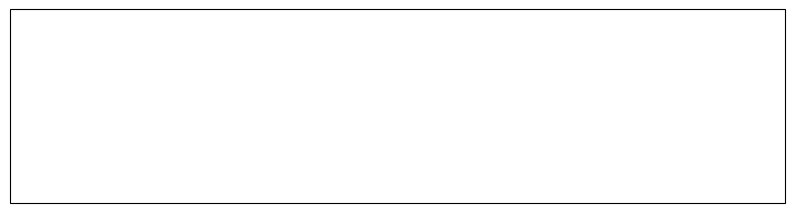

In [27]:
import cartopy.feature as cfeature

fig, ax = plt.subplots(subplot_kw={'projection': ccrs.PlateCarree()}, figsize=(10, 4))

# Set extent: lon from -180 to 180, lat from 25 to 75
ax.set_extent([-180, 180, 0, 90], crs=ccrs.PlateCarree())

# Plot the filled contours
contour = ax.contourf(
    lon, lat, neg_cov,
    #levels=np.arange(0,1,0.1),
    cmap='Blues',
    extend='both',
    transform=ccrs.PlateCarree()
)

ax.plot(location_for_test[0], location_for_test[1], marker='o', color='red', markersize=8, transform=ccrs.PlateCarree())

# Add coastlines and optional borders
ax.set_aspect(1.6)
ax.coastlines(color='black', linewidth=0.8)
ax.add_feature(cfeature.BORDERS, linewidth=0.5)

# Add colorbar
cbar = plt.colorbar(contour, ax=ax, orientation='vertical', label=r'$\frac{m^2}{s^2}$',shrink=0.5)
plt.title(r'Covariance of A and U')

plt.show()

Text(0.5, 0, 'A [m/s]')

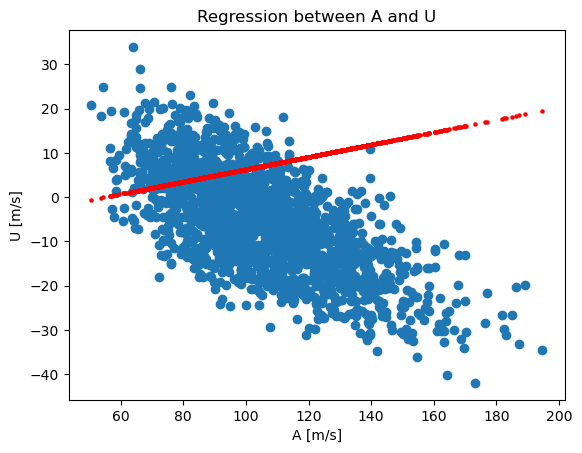

In [30]:
U_approx = (-lwa_prime_1D*alpha_1D + beta_1D)
plt.scatter(lwa_prime_1D,ucomp.sel(latitude=location_for_test[1], longitude=location_for_test[0], method='nearest').values)
plt.scatter(lwa_prime_1D,U_approx,color='Red',s=5)
plt.title('Regression between A and U')
plt.ylabel('U [m/s]')
plt.xlabel('A [m/s]')

Text(0.5, 0, 'A [m/s]')

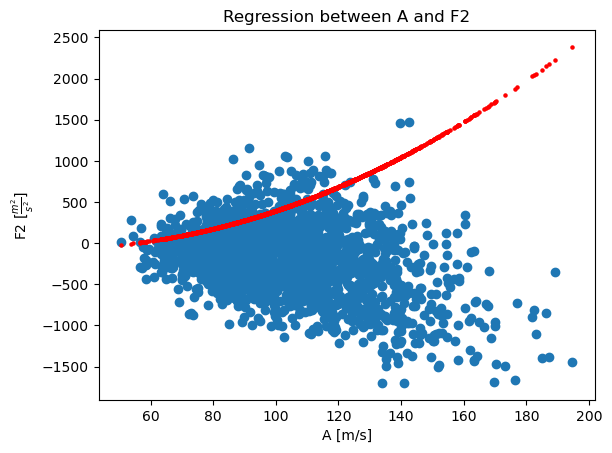

In [31]:
plt.scatter(lwa_prime_1D,F2.sel(latitude=location_for_test[1], longitude=location_for_test[0], method='nearest').values)
plt.scatter(lwa_prime_1D,F2_approx,s=5,color='Red')
plt.title('Regression between A and F2')
plt.ylabel(r'F2 [$\frac{m^2}{s^2}$]')
plt.xlabel('A [m/s]')

In [46]:
A = np.arange(0,200,1)
F2_fit = (-A*alpha_1D + beta_1D)*A*cosphi_1D + gamma_1D*A**3*cosphi_1D
F1F3_fit = (ds_zon_group_velocity_1D*A*cosphi_1D + F0_1D)

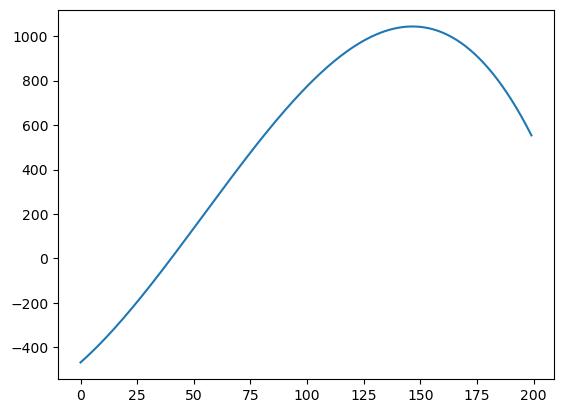

In [47]:
plt.plot(F2_fit + F1F3_fit)

Text(0.5, 0, 'A [m/s]')

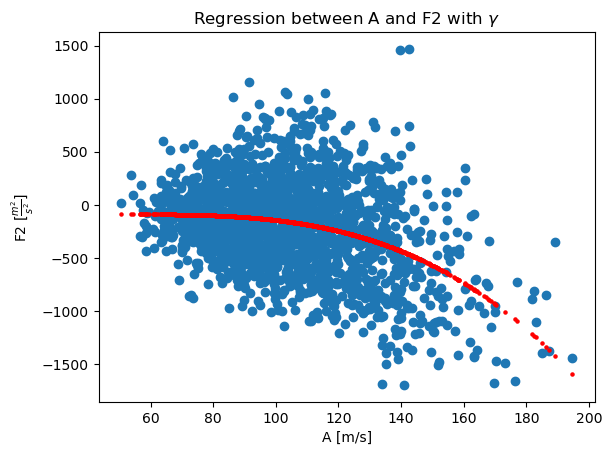

In [32]:
plt.scatter(lwa_prime_1D,F2.sel(latitude=location_for_test[1], longitude=location_for_test[0], method='nearest').values)
plt.scatter(lwa_prime_1D,F2_approx+gamma_1D*lwa_prime_1D**3*cosphi_1D,s=5,color='Red')
plt.title(r'Regression between A and F2 with $\gamma$')
plt.ylabel(r'F2 [$\frac{m^2}{s^2}$]')
plt.xlabel('A [m/s]')

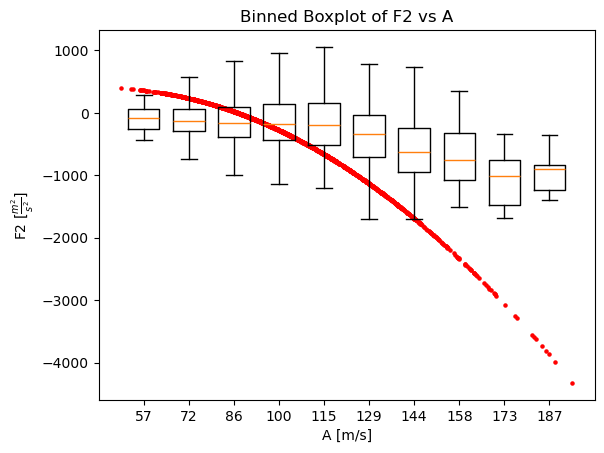

In [75]:
x_coordinate = lwa_prime_1D
F2_values = F2.sel(latitude=location_for_test[1], longitude=location_for_test[0], method='nearest').values

# Bin the x_coordinate and plot boxplots of F2_values in each bin
import pandas as pd

n_bins = 10
bins = np.linspace(np.nanmin(x_coordinate), np.nanmax(x_coordinate), n_bins+1)
bin_indices = np.digitize(x_coordinate, bins) - 1  # bin indices start at 0

# Prepare data for boxplot
binned_data = [F2_values[bin_indices == i] for i in range(n_bins)]
bin_centers = 0.5 * (bins[:-1] + bins[1:])

fig, ax = plt.subplots()
bp = ax.boxplot(binned_data, positions=bin_centers, widths=(bins[1]-bins[0])*0.7, showfliers=False)
ax.scatter(lwa_prime_1D,F2_approx,s=5,color='Red')

# Set integer x-tick labels
ax.set_xticks(bin_centers)
ax.set_xticklabels(str(int(bin_center)) for bin_center in bin_centers)#[str(i) for i in range(n_bins)])

plt.xlabel('A [m/s]')
plt.ylabel(r'F2 [$\frac{m^2}{s^2}$]')
plt.title('Binned Boxplot of F2 vs A')
plt.show()

Text(0.5, 0, 'A [m/s]')

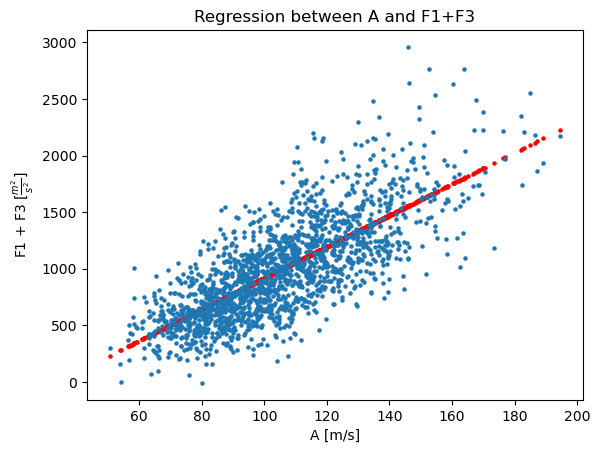

In [76]:
plt.scatter(lwa_prime_1D, F1F3_approx, s=5, color='Red')
plt.scatter(lwa_prime_1D, zonal_flux.sel(latitude=location_for_test[1], longitude=location_for_test[0], method='nearest').values, s=5)
plt.title('Regression between A and F1+F3')
plt.ylabel(r'F1 + F3 [$\frac{m^2}{s^2}$]')
plt.xlabel('A [m/s]')

Text(0, 0.5, 'transient flux [$\\frac{m^2}{s^2}$]')

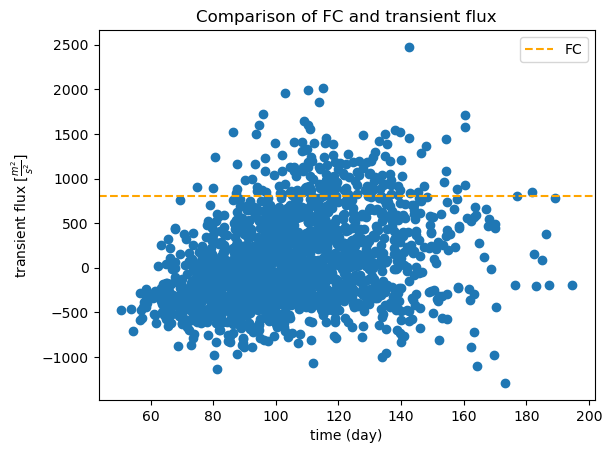

In [77]:
total_zonal_flux_1D = tot_transient_flux.sel(latitude=location_for_test[1], longitude=location_for_test[0], method='nearest').values
plt.scatter(lwa_prime_1D,total_zonal_flux_1D)
plt.axhline(FC_1D, color='orange', linestyle='--', label='FC')
plt.legend()
plt.title('Comparison of FC and transient flux')
plt.xlabel('time (day)')
plt.ylabel(r'transient flux [$\frac{m^2}{s^2}$]')

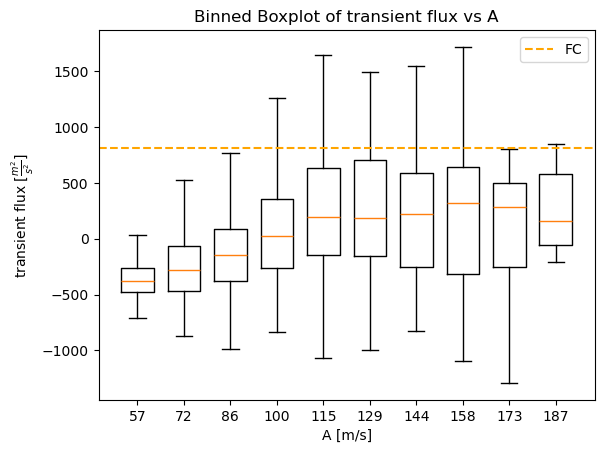

In [78]:
x_coordinate = lwa_prime_1D
F_values = total_zonal_flux_1D

# Bin the x_coordinate and plot boxplots of F2_values in each bin
import pandas as pd

n_bins = 10
bins = np.linspace(np.nanmin(x_coordinate), np.nanmax(x_coordinate), n_bins+1)
bin_indices = np.digitize(x_coordinate, bins) - 1  # bin indices start at 0

# Prepare data for boxplot
binned_data = [F_values[bin_indices == i] for i in range(n_bins)]
bin_centers = 0.5 * (bins[:-1] + bins[1:])

fig, ax = plt.subplots()
bp = ax.boxplot(binned_data, positions=bin_centers, widths=(bins[1]-bins[0])*0.7, showfliers=False)

# Set integer x-tick labels
ax.set_xticks(bin_centers)
ax.set_xticklabels(str(int(bin_center)) for bin_center in bin_centers)#[str(i) for i in range(n_bins)])

plt.axhline(FC_1D, color='orange', linestyle='--', label='FC')
plt.legend()
plt.xlabel('A [m/s]')
plt.ylabel(r'transient flux [$\frac{m^2}{s^2}$]')
plt.title('Binned Boxplot of transient flux vs A')
plt.show()

Text(0, 0.5, 'reconstructed total flux [$\\frac{m^2}{s^2}$]')

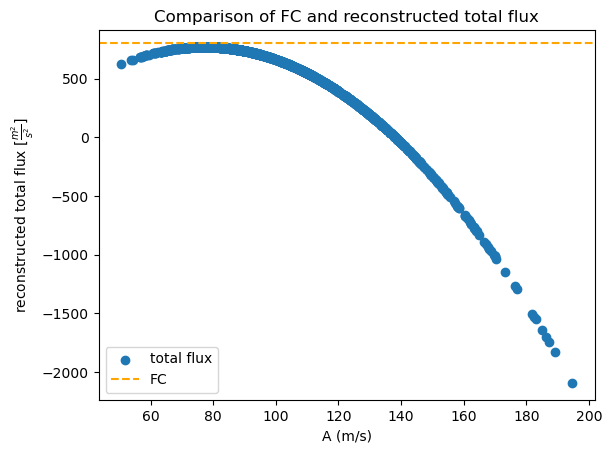

In [79]:
total_zonal_flux_1D_reconstructed = F1F3_approx + F2_approx# - FA0_1D
plt.scatter(lwa_prime_1D,total_zonal_flux_1D_reconstructed,label='total flux')
plt.axhline(FC_1D, color='orange', linestyle='--', label='FC')
plt.legend()
plt.title('Comparison of FC and reconstructed total flux')
plt.xlabel('A (m/s)')
plt.ylabel(r'reconstructed total flux [$\frac{m^2}{s^2}$]')